## 1. Importazioni e Setup

In [1]:
from scipy.stats import randint, uniform
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold


# --- Librerie Base e Data Manipulation ---
import numpy as np
import pandas as pd
import math as m
from tqdm import tqdm
from collections import Counter, defaultdict

# --- Visualizzazione ---
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from mpl_toolkits.mplot3d import Axes3D

# --- SciPy ---
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from scipy.stats import loguniform, uniform, randint

# --- Scikit-learn: Preprocessing e Imputazione ---
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

# --- Scikit-learn: Modelli (Classificazione e Regressione) ---
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    BaggingRegressor,
    GradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
)

# --- Gradient Boosting Libraries ---
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBClassifier

# --- Clustering e Manifold Learning ---
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    DBSCAN,
    KMeans,
    OPTICS,
    cluster_optics_dbscan,
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# --- Outlier Detection (PyOD e Isolation Forest) ---
from pyod.models.abod import ABOD
from pyod.models.feature_bagging import FeatureBagging
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from pyod.models.loda import LODA
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

# --- Model Selection e Pipeline ---
from sklearn.model_selection import (
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# --- Metriche ---
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    roc_curve,
    auc,
    RocCurveDisplay,
    silhouette_samples,
    silhouette_score,
)

## 2. Caricamento Dataset

In [2]:
# dataset
df = pd.read_parquet("df_pulito.parquet")

# Train Test sii
pciat_cols = [f"PCIAT-PCIAT_{i:02d}" for i in range(1, 21)]
X = df.drop(columns=["sii", "risultati", "PCIAT-PCIAT_Total", "id"] + pciat_cols)
y = df["sii"]
X_train_nos, X_test_nos, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=222)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_nos)
X_test = scaler.transform(X_test_nos)

smote = SMOTE(random_state=222)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)



In [3]:
def plot_roc_and_cm(estimator, X_test, y_test, model_name="Model"):
    """
    Visualizza la curva ROC multiclasse (One-vs-Rest) e la Confusion Matrix.
    """

    # ── ROC ──────────────────────────────────────────────────────────────────
    classes = np.unique(y_test)
    n_classes = len(classes)

    y_test_bin = label_binarize(y_test, classes=classes)

    if hasattr(estimator, "predict_proba"):
        y_score = estimator.predict_proba(X_test)
    elif hasattr(estimator, "decision_function"):
        y_score = estimator.decision_function(X_test)
    else:
        
        raise AttributeError("L'estimatore fornito non ha predict_proba o decision_function.")

    # Fix caso binario
    if n_classes == 2 and y_score.ndim > 1:
        y_score = y_score[:, 1]

    fpr, tpr, roc_auc = dict(), dict(), dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Micro-average
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    # Macro-average
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # Plot ROC
    plt.figure(figsize=(10, 8))
    plt.plot(fpr["micro"], tpr["micro"],
             label=f'Micro-average ROC (AUC = {roc_auc["micro"]:.2f})',
             color='deeppink', linestyle=':', linewidth=4)
    plt.plot(fpr["macro"], tpr["macro"],
             label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.2f})',
             color='navy', linestyle=':', linewidth=4)

    colors = ['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple']
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'Classe {classes[i]} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Curve ROC Multiclasse - {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    # ── CONFUSION MATRIX ─────────────────────────────────────────────────────
    y_pred = estimator.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Classe Reale')
    plt.xlabel('Classe Predetta')
    plt.tight_layout()
    plt.show()

## SVM

In [4]:
# IPERPARAMETRI
# si usano valori che terminano con 1 perchè non ha senso considerare valori sullo stesso ordine di grandezza geometrico:
# Come formalizzato nei materiali didattici di riferimento, l'esplorazione ottimale dei parametri sensibili (inclusi 
# il parametro di costo C delle Support Vector Machines o i tassi di apprendimento) deve essere effettuata attraversando una scala 
# logaritmica pura (es. [0.001, 0.01, 0.1, 1, 10, 100, 1000]) per coprire spettri dimensionali reciprocamente distanti.
# Fonte Scientifica Esterna: Nel lavoro fondamentale di Yoshua Bengio, "Practical Recommendations for Gradient-Based Training of 
# Deep Architectures" (2012), viene dimostrato che il learning rate deve essere campionato applicando una trasformazione logaritmica, 
# definita dall'equazione η=10r, dove l'esponente r è una variabile casuale estratta uniformemente da un intervallo di interi o reali 
# (es. r∈[−4,−1]). I numeri come 0.1, 0.01 o 0.001 non sono altro che i risultati discreti determinati quando l'esponente r assume 
# valori interi pari a -1, -2 o -3.

param_dist_svm = {
    'C': [0.001, 0.01, 0.1, 1, 10], #, 100],
    'gamma': ['scale' , 'auto', 0.001, 0.01, 0.1, 1.0],
    'kernel': ['rbf'] # ,'poly', 'linear']
}
# 3. Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 4. RandomizedSearchCV (30 iterazioni)
random_search_svm = RandomizedSearchCV(
    estimator=SVC(probability=True, random_state=222), # probability=True è necessario per calcolare le probabilità per la ROC curve,
    param_distributions=param_dist_svm,
    n_iter=15,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=2
)
print("Avvio della RandomizedSearchCV per SVM...")
random_search_svm.fit(X_train, y_train)

# Risultati migliori
print(f"\nMigliori iperparametri trovati: {random_search_svm.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_svm.best_score_:.4f}")

Avvio della RandomizedSearchCV per SVM...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


Traceback (most recent call last):
  File "<frozen runpy>", line 189, in _run_module_as_main
  File "<frozen runpy>", line 112, in _get_module_details
  File "/opt/anaconda3/lib/python3.13/site-packages/joblib/__init__.py", line 114, in <module>
    from .memory import Memory
  File "/opt/anaconda3/lib/python3.13/site-packages/joblib/memory.py", line 29, in <module>
    from ._store_backends import CacheWarning  # noqa
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.13/site-packages/joblib/_store_backends.py", line 17, in <module>
    from .backports import concurrency_safe_rename
  File "/opt/anaconda3/lib/python3.13/site-packages/joblib/backports.py", line 112, in <module>
    import numpy as np
  File "/opt/anaconda3/lib/python3.13/site-packages/numpy/__init__.py", line 114, in <module>
    from numpy.__config__ import show_config
  File "/opt/anaconda3/lib/python3.13/site-packages/numpy/__config__.py", line 4, in <module>
    from numpy._core._multi

KeyboardInterrupt: 

Accuracy sul Test Set: 0.6611
F1-score per classe: [0.80453706 0.21576763 0.14814815 0.        ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.73      0.89      0.80      1705
           1       0.29      0.17      0.22       450
           2       0.28      0.10      0.15       297
           3       0.00      0.00      0.00        18

    accuracy                           0.66      2470
   macro avg       0.32      0.29      0.29      2470
weighted avg       0.59      0.66      0.61      2470

Risultati del tuning salvati in 'svm_random_search_results.csv'


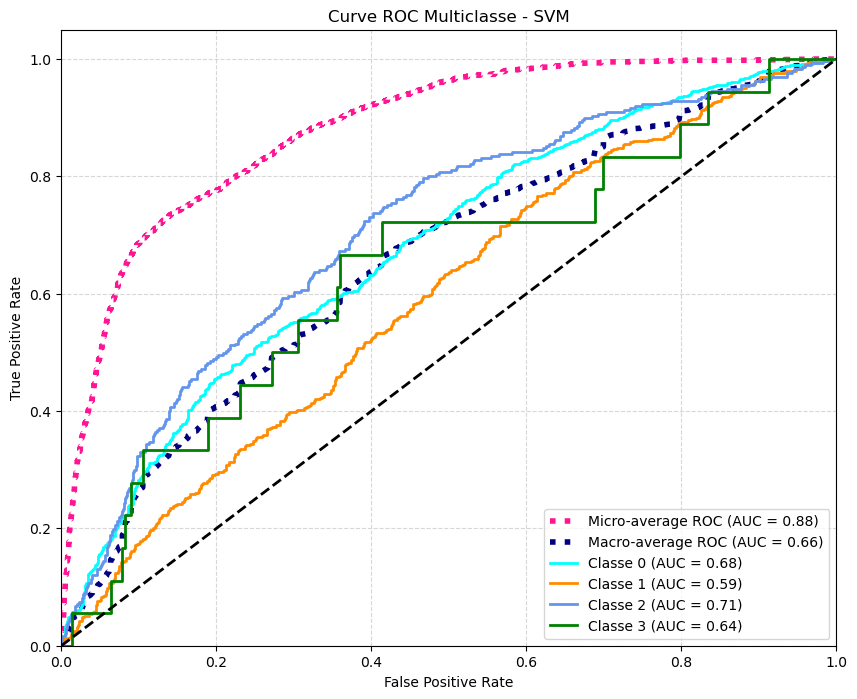

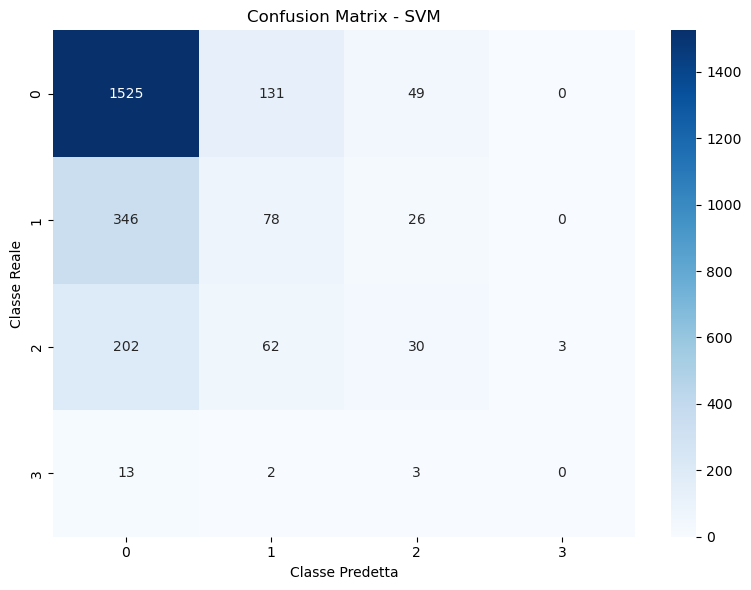

In [ ]:
# Valutazione sul Test Set reale
best_svm = random_search_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_svm))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_svm, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_svm))

# Salvataggio dei risultati in CSV
svm_results_df = pd.DataFrame(random_search_svm.cv_results_)
#svm_results_df.to_csv("csv_classificazione/svm_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'svm_random_search_results.csv'")

# Visualizzazione della curva ROC
plot_roc_and_cm(best_svm, X_test, y_test, 'SVM')

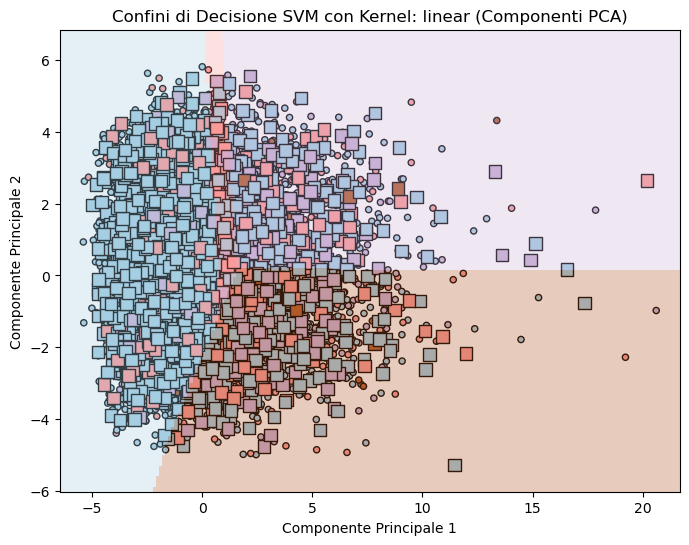

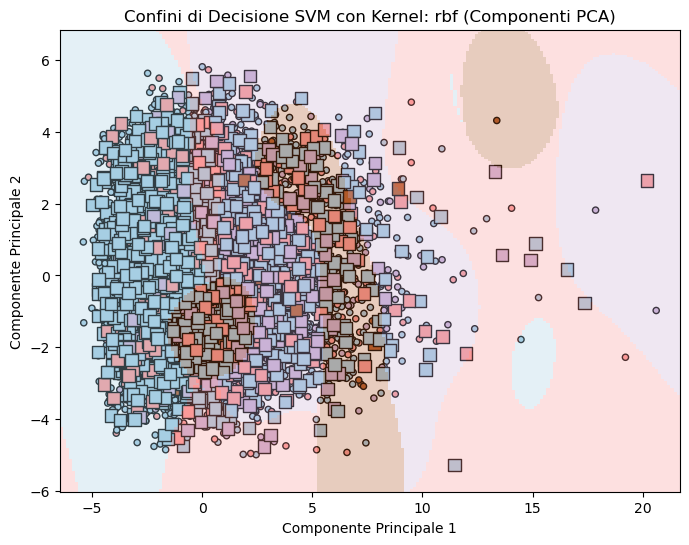

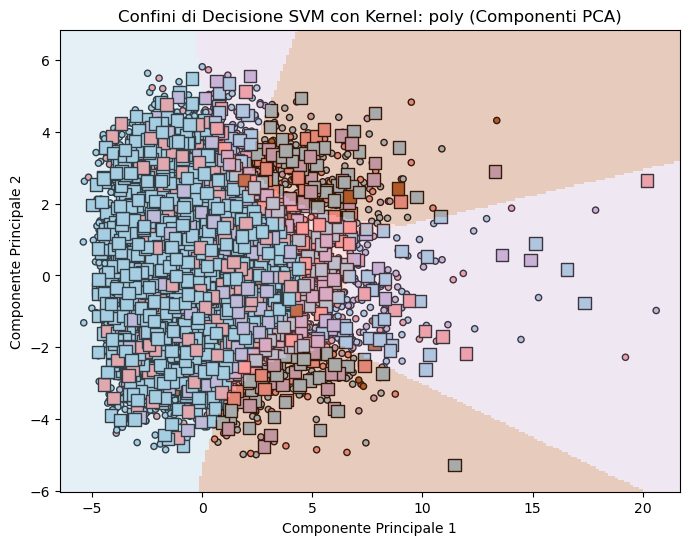

In [ ]:
# Visualizzazione dei confini di decisione in 2D tramite PCA (esemplificazione)
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train) 
X_test_pca = pca.transform(X_test)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
XX, YY = np.mgrid[x_min:x_max:200j, y_min:y_max:200j]

for kernel in ('linear', 'rbf', 'poly'):
    # Addestriamo la SVM sulle sole 2 componenti PCA per la visualizzazione grafica
    clf_pca = SVC(kernel=kernel, C=1.8, gamma='scale', class_weight='balanced', random_state=222)
    clf_pca.fit(X_train_pca, y_train)

    plt.figure(figsize=(8, 6))
    
    # Punti di Training (cerchi piccoli) e Test (quadrati grandi)
    plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap=plt.cm.Paired, edgecolors='k', s=20)
    plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap=plt.cm.Paired, edgecolors='k', s=80, marker='s')

    # Predizione sulla griglia 2D
    Z = clf_pca.predict(np.c_[XX.ravel(), YY.ravel()])
    Z = Z.reshape(XX.shape)

    plt.pcolormesh(XX, YY, Z, cmap=plt.cm.Paired, alpha=0.3, shading='auto')
    plt.title(f'Confini di Decisione SVM con Kernel: {kernel} (Componenti PCA)')
    plt.xlabel('Componente Principale 1')
    plt.ylabel('Componente Principale 2')
    plt.show()

## RandomForest

In [ ]:
param_dist_rf = {
    'n_estimators':      [100, 150, 200, 250, 300], #, 400, 450, 500, 600, 700],
    'max_depth':         [None, 15, 20, 30], #gli alberi di una Random Forest devono essere unpruned (non potati), lasciati liberi di crescere fino a quando ogni foglia è pura. Limitare la profondità a 6 o 7 introduce un bias artificiale sull'induttore di base, forzando la foresta a lavorare con weak classifiers troppo deboli.
    'min_samples_split': [2, 5, 8, 9, 10, 11, 12, 15],
    'min_samples_leaf':  [1, 2, 3, 4, 8],
    'criterion':         ['gini', 'entropy'],
    'max_features':      ['sqrt', 'log2'],
    'class_weight':      ['balanced', 'balanced_subsample'] # altri valori neanche li considero
}

# 3. StratifiedKFold (Invariata)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 4. RandomizedSearchCV (Applicata alla pipeline con i parametri corretti)
random_search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=222, n_jobs=-1),
    param_distributions=param_dist_rf, # Utilizza il dizionario corretto
    n_iter=15,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=2
)

print("Avvio della RandomizedSearchCV per Random Forest...")
random_search_rf.fit(X_train_nos, y_train)

# Risultati migliori
print(f"\nMigliori iperparametri trovati: {random_search_rf.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_rf.best_score_:.4f}")

Avvio della RandomizedSearchCV per Random Forest...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=100; total time=   1.1s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=100; total time=   1.1s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=100; total time=   1.1s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=100; total time=   1.2s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=8, min_samples_split=5, n_estimators=100; total time=   1.3s
[CV] END class_we

Accuracy sul Test Set: 0.5968
F1-score per classe: [0.75452038 0.29157667 0.30678466 0.10958904]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.79      0.72      0.75      1705
           1       0.28      0.30      0.29       450
           2       0.27      0.35      0.31       297
           3       0.07      0.22      0.11        18

    accuracy                           0.60      2470
   macro avg       0.35      0.40      0.37      2470
weighted avg       0.63      0.60      0.61      2470

Risultati del tuning salvati in 'rf_af_halving_search_results.csv'


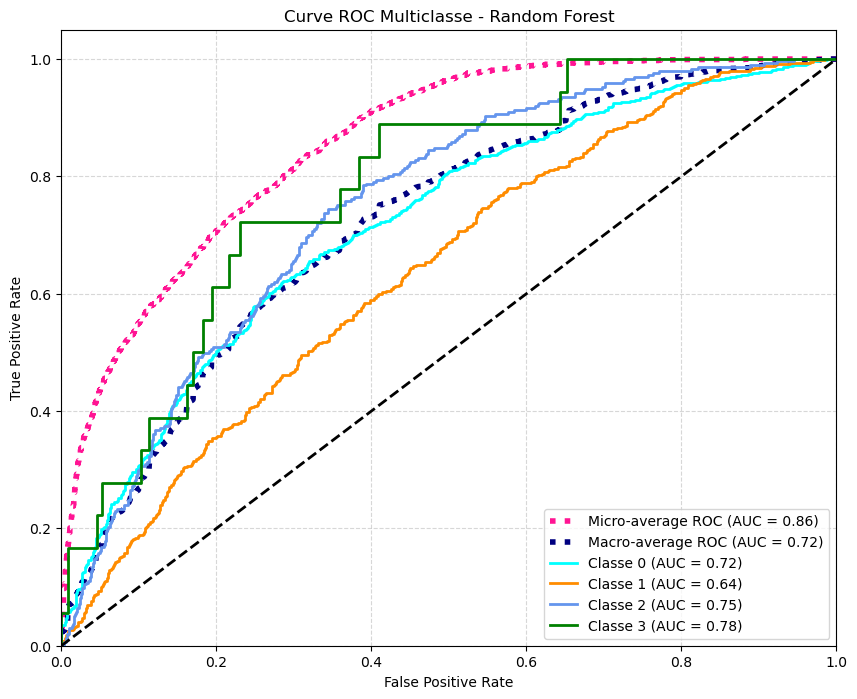

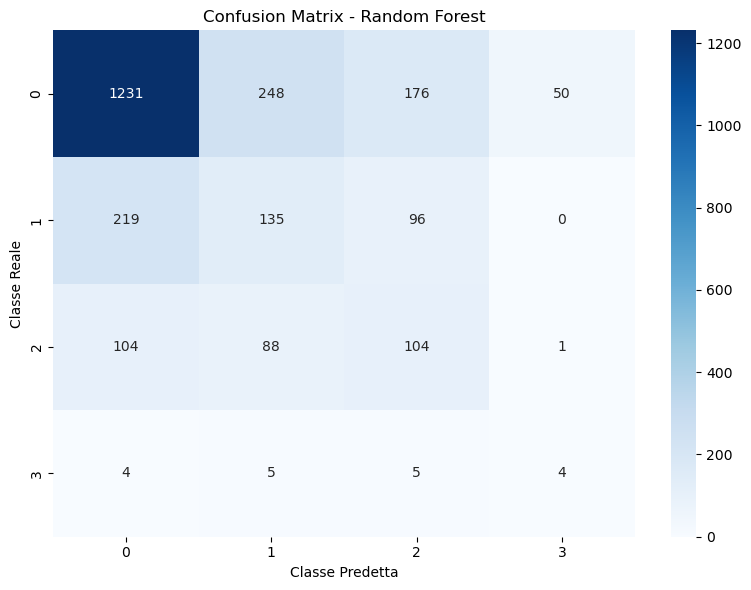

In [ ]:
# Valutazione sul Test Set
# valori oltre al 300 di n estimator aumentano solo il carico computazionale e migliorano di pochissimo i risultati
best_rf = random_search_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_nos)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_rf))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_rf, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_rf))

rf_results_df = pd.DataFrame(random_search_rf.cv_results_)
#rf_results_df.to_csv("csv_classificazione/rf_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'rf_af_halving_search_results.csv'")
plot_roc_and_cm(best_rf, X_test_nos, y_test, "Random Forest")

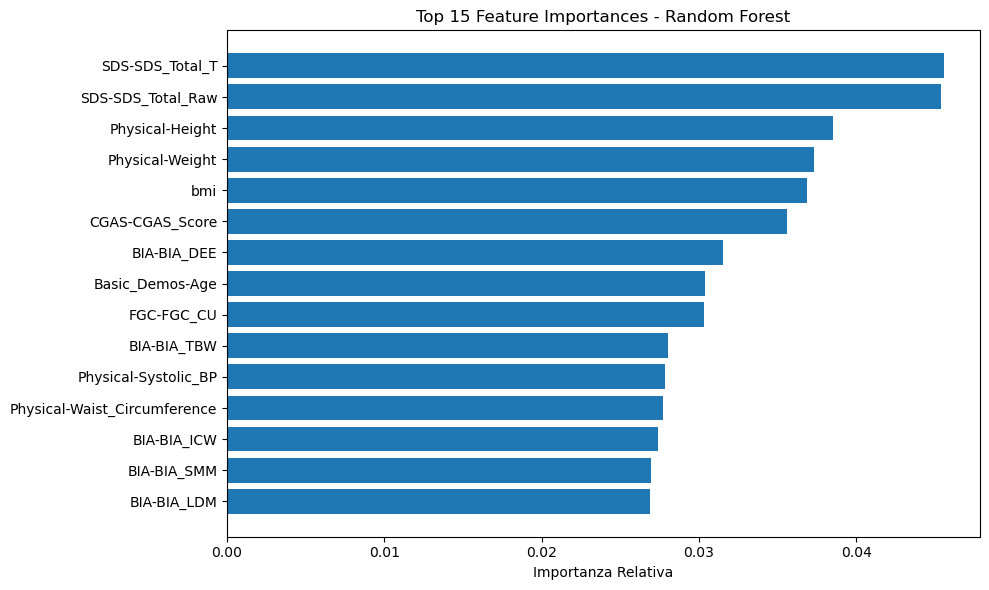

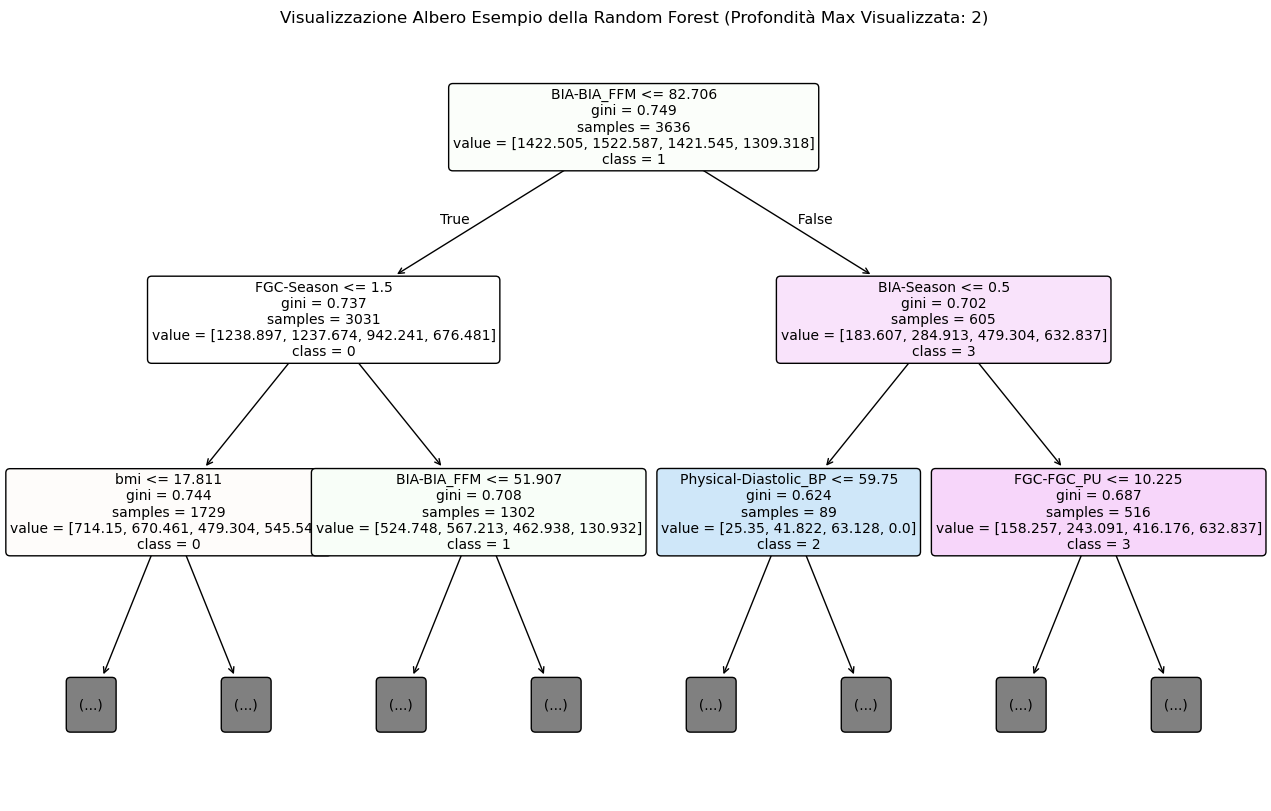

In [ ]:
nbr_features = 15
tree_feature_importances = best_rf.feature_importances_
sorted_idx = tree_feature_importances.argsort()[-nbr_features:]

feature_names = np.array(X.columns)

plt.figure(figsize=(10, 6))
plt.barh(np.arange(len(sorted_idx)), tree_feature_importances[sorted_idx])
plt.yticks(np.arange(len(sorted_idx)), feature_names[sorted_idx])
plt.title(f'Top {nbr_features} Feature Importances - Random Forest')
plt.xlabel('Importanza Relativa')
plt.tight_layout()
plt.show()

# Visualizzazione di un singolo albero estratto direttamente dalla foresta
plt.figure(figsize=(16, 10))
plot_tree(
    best_rf.estimators_[0],
    feature_names=feature_names,
    class_names=[str(c) for c in np.unique(y)],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=2
)
plt.title("Visualizzazione Albero Esempio della Random Forest (Profondità Max Visualizzata: 2)")
plt.show()

## Bagging

In [ ]:
# ho provato prima a provare la grid anche per il randomforest ma esce stranamente meglio con i valori predefiniti

param_dist_bagging = {
    "n_estimators": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "max_samples": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "max_features": [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
}

# 3. StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 4. RandomizedSearchCV
random_search_bagging = RandomizedSearchCV(
    estimator=BaggingClassifier(
        estimator=RandomForestClassifier(random_state=222),
        random_state=222),
    param_distributions=param_dist_bagging,
    n_iter=20,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=1
)

print("Avvio della RandomizedSearchCV per Bagging Classifier...")
random_search_bagging.fit(X_train, y_train)

# Risultati migliori
print(f"\nMigliori iperparametri trovati: {random_search_bagging.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_bagging.best_score_:.4f}")

Avvio della RandomizedSearchCV per Bagging Classifier...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


Exception ignored in: <function ResourceTracker.__del__ at 0x106f89760>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Exception ignored in: <function ResourceTracker.__del__ at 0x104c21760>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  F


Migliori iperparametri trovati: {'n_estimators': 100, 'max_samples': 0.8, 'max_features': 1.0}
Miglior F1-macro in Cross-Validation: 0.2197


Accuracy sul Test Set: 0.6955
F1-score per classe: [0.82171291 0.05462185 0.01328904 0.        ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.70      1.00      0.82      1705
           1       0.50      0.03      0.05       450
           2       0.50      0.01      0.01       297
           3       0.00      0.00      0.00        18

    accuracy                           0.70      2470
   macro avg       0.42      0.26      0.22      2470
weighted avg       0.63      0.70      0.58      2470

Risultati del tuning salvati in 'bagging_random_search_results.csv'


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


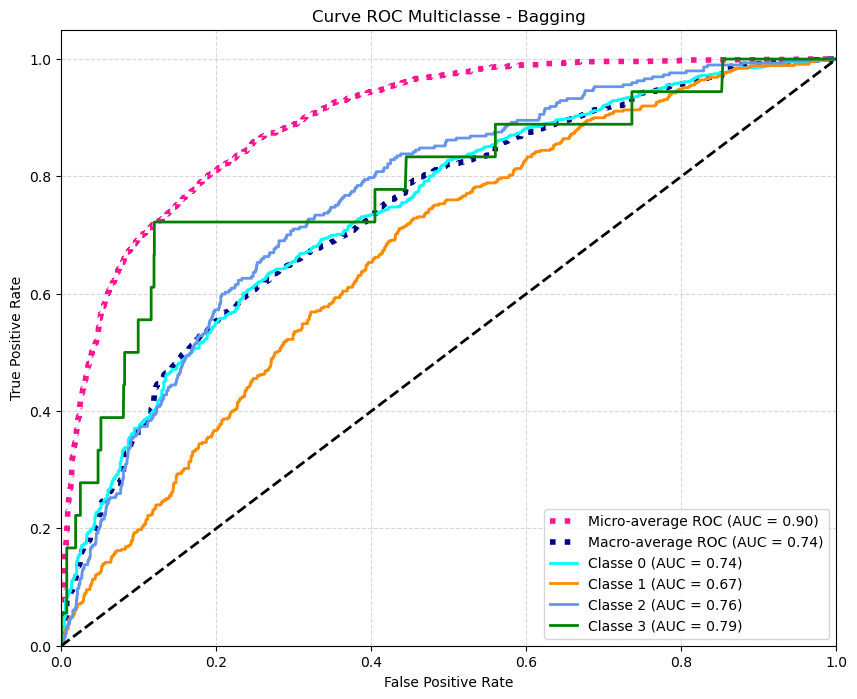

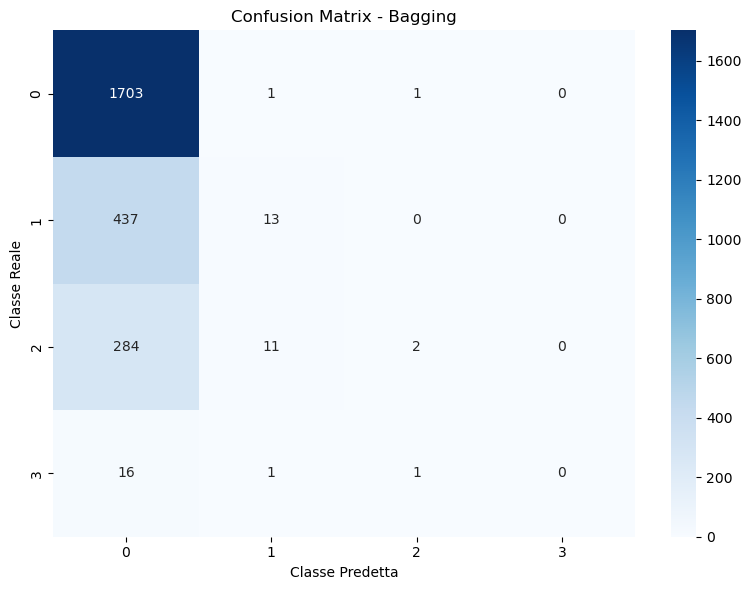

In [ ]:
# Valutazione sul Test Set reale
best_bagging = random_search_bagging.best_estimator_
y_pred_bagging = best_bagging.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_bagging))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_bagging, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_bagging))

# Salvataggio dei risultati in CSV
bagging_results_df = pd.DataFrame(random_search_bagging.cv_results_)
#bagging_results_df.to_csv("csv_classificazione/bagging_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'bagging_random_search_results.csv'")

# ROC and CM
plot_roc_and_cm(random_search_bagging, X_test, y_test, "Bagging")


## AdaBoost

In [ ]:
#tecnicamente adaboost è per le binarie ma viene usato l'algoritmo SAMME
# usato smote qui
param_grid_adaboost = {
    'n_estimators': [50, 100, 150, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]
}

# 2. StratifiedKFold coerente (5 splits reali)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 3. Passaggio a GridSearchCV per un'esplorazione esaustiva di 35 combinazioni
grid_search_adaboost = GridSearchCV(
    estimator=AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=222),
        random_state=222
    ),
    param_grid=param_grid_adaboost,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Avvio GridSearchCV per AdaBoost...")
grid_search_adaboost.fit(X_train_resampled, y_train_resampled)

print("\n" + "="*40)
print(f"Migliori iperparametri trovati:\n{grid_search_adaboost.best_params_}")
print(f"Miglior F1-macro in CV: {grid_search_adaboost.best_score_:.4f}")
print("="*40)

Avvio GridSearchCV per AdaBoost...
Fitting 5 folds for each of 25 candidates, totalling 125 fits

Migliori iperparametri trovati:
{'learning_rate': 1.0, 'n_estimators': 300}
Miglior F1-macro in CV: 0.5548


Accuracy sul Test Set: 0.5053
F1-score per classe: [0.67074742 0.25       0.27670753 0.02264151]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.74      0.61      0.67      1705
           1       0.23      0.28      0.25       450
           2       0.29      0.27      0.28       297
           3       0.01      0.17      0.02        18

    accuracy                           0.51      2470
   macro avg       0.32      0.33      0.31      2470
weighted avg       0.59      0.51      0.54      2470

Risultati del tuning salvati in 'adaboost_random_search_results.csv'


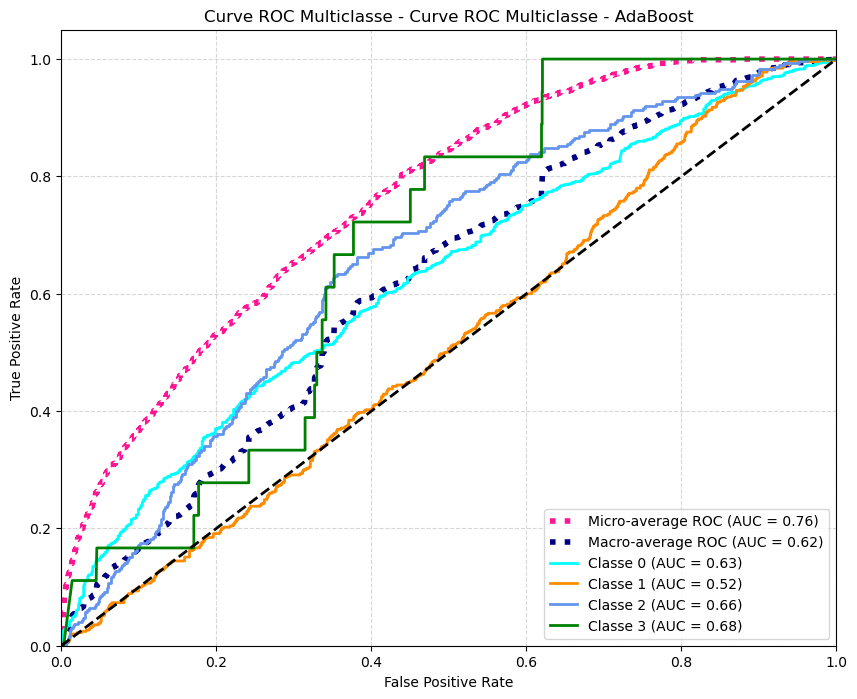

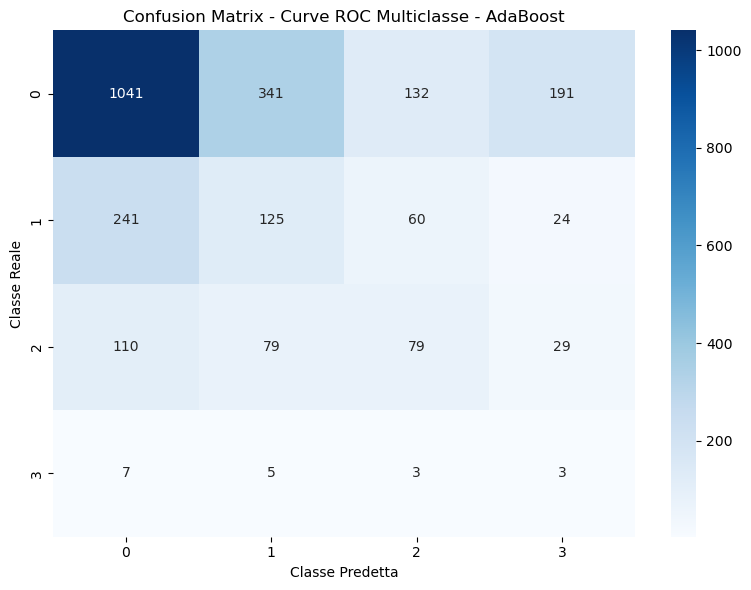

In [ ]:
best_adaboost = grid_search_adaboost.best_estimator_
y_pred_adaboost = best_adaboost.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_adaboost))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_adaboost, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_adaboost))

# Salvataggio dei risultati in CSV
adaboost_results_df = pd.DataFrame(grid_search_adaboost.cv_results_)
#adaboost_results_df.to_csv("csv_classificazione/adaboost_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'adaboost_random_search_results.csv'")

# Visualizzazione della curva ROC
plot_roc_and_cm(best_adaboost, X_test, y_test, "Curve ROC Multiclasse - AdaBoost")

## GradientBoosting

In [ ]:
#usato smote
param_dist_gb = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.01, 0.1],
    #di solito si usano da 8 a 32 leaves
    'max_leaf_nodes': [ 8, 16],# 32],
    # Opzioni nette per il campionamento delle righe
    'subsample': [0.8, 0.9, 1.0]
}

#In sede d'esame o nella relazione richiesta per dm2_project_guidelines_25_26.pptx.pdf, devi saper argomentare la forte 
# interazione tra subsample e learning_rate:   
# Principio del Boosting: Se riduci subsample (es. a 0.8), devi contemporaneamente impostare un learning_rate basso (es. 0.01 o 0.05) 
# e aumentare il numero di alberi (n_estimators). Questo approccio, noto come shrinkage, rallenta la discesa lungo il gradiente della 
# loss function ma garantisce una convergenza estremamente robusta, riducendo drasticamente l'errore di generalizzazione.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

random_search_gb = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=222),
    param_distributions=param_dist_gb,
    n_iter=20,  # veloci da addestrare, secondo gemini 60 è il gold standard boh. niente ci mette molto         
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,          # Sfrutta tutti i core della CPU
    random_state=222,
    verbose=1           # Mostra lo stato di avanzamento sintetico
)

print("Avvio della RandomizedSearchCV con iperparametri discreti...")
random_search_gb.fit(X_train_resampled, y_train_resampled)

# Risultati migliori
print("\n" + "="*40)
print(f"Migliori iperparametri trovati:\n{random_search_gb.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_gb.best_score_:.4f}")
print("="*40 + "\n")

Avvio della RandomizedSearchCV con iperparametri discreti...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Migliori iperparametri trovati:
{'subsample': 0.9, 'n_estimators': 200, 'max_leaf_nodes': 16, 'learning_rate': 0.1}
Miglior F1-macro in Cross-Validation: 0.8057



Accuracy sul Test Set: 0.6769
F1-score per classe: [0.81446541 0.19849624 0.23529412 0.11764706]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.74      0.91      0.81      1705
           1       0.31      0.15      0.20       450
           2       0.39      0.17      0.24       297
           3       0.12      0.11      0.12        18

    accuracy                           0.68      2470
   macro avg       0.39      0.33      0.34      2470
weighted avg       0.61      0.68      0.63      2470

Risultati del tuning salvati in 'gradient_boosting_random_search_results.csv'


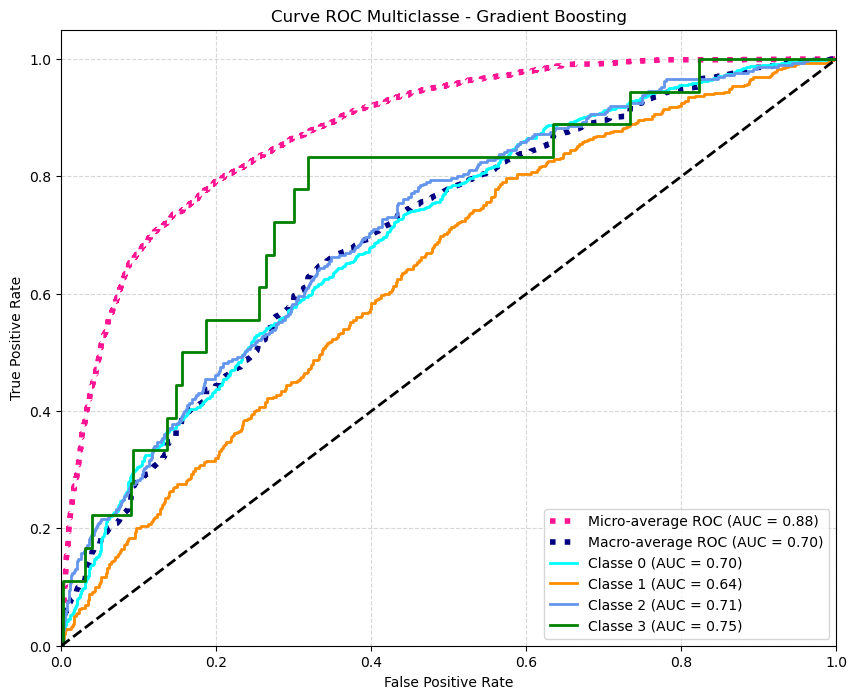

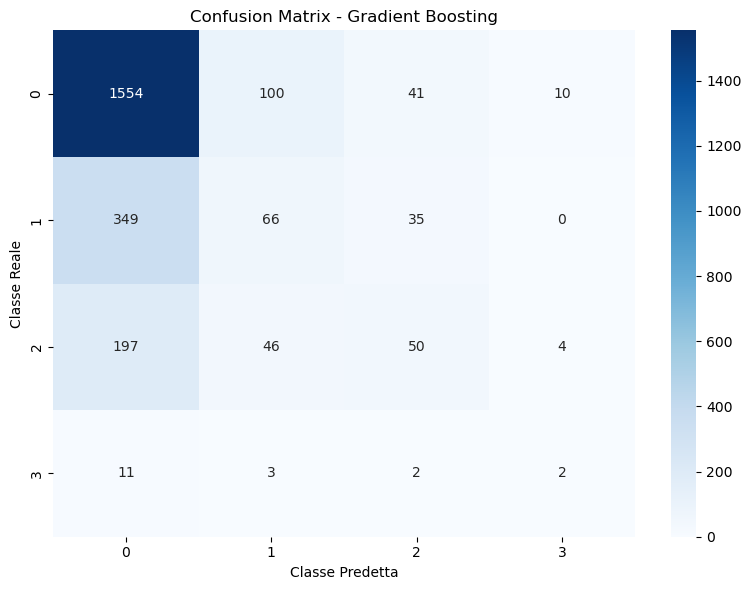

In [ ]:
# Valutazione sul Test Set reale
best_gb = random_search_gb.best_estimator_
y_pred_gb = best_gb.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_gb))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_gb, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_gb))

# Salvataggio dei risultati in CSV
gb_results_df = pd.DataFrame(random_search_gb.cv_results_)
#gb_results_df.to_csv("csv_classificazione/gradient_boosting_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'gradient_boosting_random_search_results.csv'")

# Visualizzazione della curva ROC
plot_roc_and_cm(best_gb, X_test, y_test, "Gradient Boosting")

## XGBoost

In [ ]:
"""
XGBoost per classificazione multiclasse con SMOTE.

TEORIA DEI PARAMETRI E DELLE LORO INTERAZIONI:
-----------------------------------------------
XGBoost costruisce alberi in sequenza: ogni nuovo albero corregge gli errori
residui del precedente (gradient boosting). La sua forza rispetto a GBM classico
sta nel sistema di regolarizzazione nativo e nel supporto al campionamento colonne.

SISTEMA DI SHRINKAGE (interazione critica per l'esame):
  learning_rate (eta) ↓  →  n_estimators ↑
  Abbassare il learning_rate riduce il contributo di ogni singolo albero,
  rallentando deliberatamente la discesa sul gradiente della loss function.
  Questo approccio (shrinkage) riduce la varianza del modello finale a costo
  di più alberi. La combinazione ottimale NON è trovabile separando i due
  parametri: vanno esplorati insieme.

SISTEMA DI REGOLARIZZAZIONE (gamma, reg_alpha, reg_lambda non sono indipendenti):
  - gamma: pruning strutturale. Agisce PRIMA di creare uno split: se la
    riduzione di loss attesa è < gamma, il nodo non viene diviso.
    È una regolarizzazione sulla struttura dell'albero.
  - reg_lambda (L2): penalizza i pesi (leaf scores) troppo grandi.
    Agisce DOPO la struttura, sulla magnitudine dei valori foglia.
    Default XGBoost = 1 (già attivo). Scendere sotto 1 rimuove la penalità.
  - reg_alpha (L1): incoraggia la sparsità dei pesi foglia, azzerando
    contributi irrilevanti. Utile con molte feature (feature selection implicita).
  I tre operano su livelli diversi: gamma controlla la topologia,
  lambda/alpha controllano i valori. Usarli insieme è più potente che usarli
  singolarmente.

CAMPIONAMENTO (subsample e colsample_bytree):
  subsample < 1.0 → stochastic gradient boosting (righe)
  colsample_bytree < 1.0 → random subspace method (colonne per albero)
  Entrambi introducono stocasticità decorrelando gli alberi, come nel Random
  Forest. Combinati con learning_rate basso danno la massima robustezza.

max_depth vs gamma:
  XGBoost tollera max_depth più elevati rispetto a GBM classico PROPRIO perché
  gamma, reg_alpha e reg_lambda possono potare retroattivamente l'albero.
  Un albero con max_depth=7 e gamma=0.5 sarà molto più semplice di quanto
  max_depth suggerisca.
"""

# ---------------------------------------------------------------------------
# SPAZIO DEI PARAMETRI — scelte motivate
# ---------------------------------------------------------------------------
param_dist_xgb = {
    # Numero di alberi: esplora range ampio perché interagisce con learning_rate.
    # Con learning_rate=0.01 servono almeno 300+ alberi per convergere.
    'n_estimators': [100, 200, 300, 500],

    # Profondità: XGBoost regge valori più alti di GBM grazie alla
    # regolarizzazione nativa. max_depth=7 con gamma>0 produce alberi
    # effettivamente più semplici di quanto il numero suggerisca.
    'max_depth': [3, 5, 7],

    # Shrinkage: valori bassi = convergenza lenta ma robusta.
    # 0.01 richiede n_estimators alto; 0.1 è aggressivo ma veloce.
    # La coppia (learning_rate, n_estimators) è la più influente in assoluto.
    'learning_rate': [0.01, 0.05, 0.1],

    # Campionamento righe: 0.7 introduce molta stocasticità (riduce varianza,
    # aumenta bias lievemente). Con learning_rate basso si compensa bene.
    'subsample': [0.7, 0.8, 0.9, 1.0],

    # Campionamento colonne per albero: decorrela gli alberi come in RF.
    # Particolarmente utile con molte feature ridondanti.
    'colsample_bytree': [0.7, 0.8, 1.0],

    # Pruning strutturale: 0 = nessun pruning, 0.5 = moderato, 1.0 = aggressivo.
    # Valori > 0.2 hanno effetto visibile solo con max_depth alto.
    'gamma': [0, 0.1, 0.3, 0.5],

    # L1: scala logaritmica perché l'effetto è non-lineare.
    # 0 = disattivo, 0.01 = sparsità lieve, 0.1 = moderata, 1 = forte.
    'reg_alpha': [0, 0.01, 0.1, 1.0],

    # L2: default XGBoost è già 1. Scendere a 0.5 riduce la penalità,
    # salire a 5 la rafforza molto. Range più ampio del tuo originale.
    'reg_lambda': [0.5, 1.0, 2.0, 5.0],
}

# ---------------------------------------------------------------------------
# CROSS-VALIDATION — StratifiedKFold per preservare le proporzioni di classe
# anche dopo SMOTE (che ha già bilanciato solo il training set)
# ---------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------------------------------------------------------
# RANDOMIZED SEARCH
# ---------------------------------------------------------------------------
random_search_xgb = RandomizedSearchCV(
    estimator=XGBClassifier(
        objective='multi:softprob',
        # eval_metric è deliberatamente ESCLUSO dal costruttore:
        # in RandomizedSearchCV non si passa eval_set a .fit(), quindi
        # eval_metric sarebbe inerte. La metrica di selezione è 'f1_macro'
        # nel parametro scoring qui sotto — quella conta davvero.
        # Se si volesse usare early_stopping, servirebbe un loop manuale
        # o un callback custom, non RandomizedSearchCV standard.
        use_label_encoder=False,  # sopprime warning deprecation XGBoost >= 1.6
        random_state=222,
        n_jobs=1,  # XGBoost ha parallelismo interno: n_jobs qui si scontra
                   # con n_jobs=-1 di RandomizedSearchCV causando overhead.
                   # Meglio lasciare la parallelizzazione a RandomizedSearchCV.
    ),
    param_distributions=param_dist_xgb,
    # Con 9 iperparametri e spazio ~4^6 × 3^3 ≈ 110k combinazioni,
    # n_iter=40 copre ~0.04% ma con campionamento casuale ben distribuito.
    # n_iter=20 è il minimo accettabile; 40 è il gold standard per questo spazio.
    n_iter=20,
    scoring='f1_macro',   # corretto per classi sbilanciate (pre-SMOTE erano sbilanciate)
    cv=cv,
    n_jobs=-1,            # parallelizza i fold/iter, non il singolo modello
    random_state=222,      # stesso seed di tutto il progetto per riproducibilità
    verbose=1,
    error_score='raise'   # fa saltare subito se una combinazione è invalida,
                          # invece di silenziare errori e produrre NaN nei risultati
)

print("Avvio RandomizedSearchCV XGBoost...")
random_search_xgb.fit(X_train_resampled, y_train_resampled)

print("\n" + "="*50)
print(f"Migliori iperparametri:\n{random_search_xgb.best_params_}")
print(f"Miglior F1-macro (CV): {random_search_xgb.best_score_:.4f}")
print("="*50)

Avvio RandomizedSearchCV XGBoost...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/opt/anaconda3/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [08:03:55] WARNING: /var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_abwcuua5oq/croot/xgboost-split_1749630928197/work/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [08:03:55] WARNING: /var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_abwcuua5oq/croot/xgboost-split_1749630928197/work/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [08:03:55] WARNING: /var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_abwcuua5oq/croot/xgboost-split_1749630928197/work/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.13/site-pa


Migliori iperparametri:
{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}
Miglior F1-macro (CV): 0.9095


Accuracy sul Test Set: 0.6879
F1-score per classe: [0.82340862 0.17252396 0.20151134 0.0952381 ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.73      0.94      0.82      1705
           1       0.31      0.12      0.17       450
           2       0.40      0.13      0.20       297
           3       0.33      0.06      0.10        18

    accuracy                           0.69      2470
   macro avg       0.44      0.31      0.32      2470
weighted avg       0.61      0.69      0.62      2470

Risultati del tuning salvati in 'xgboost_random_search_results.csv'


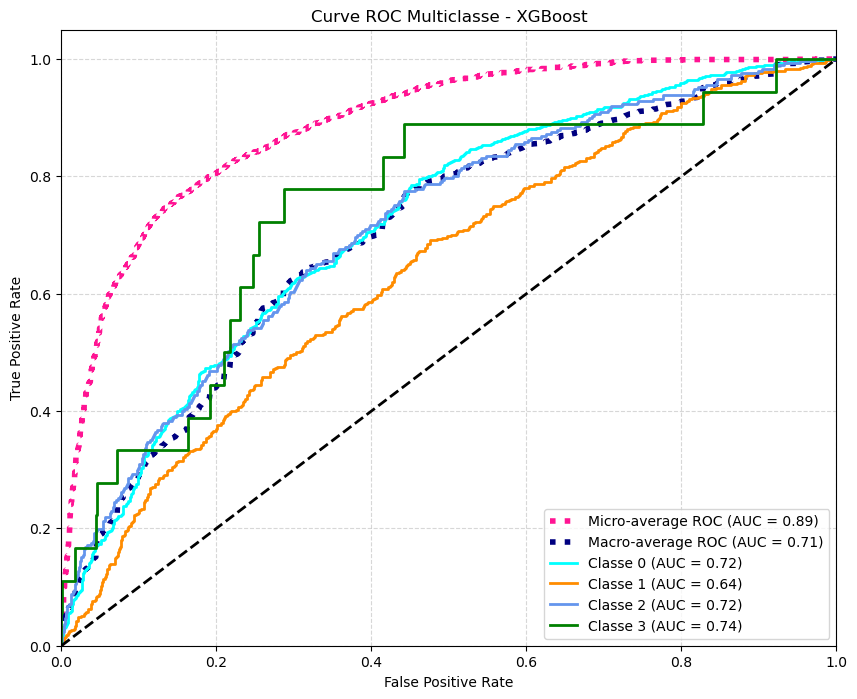

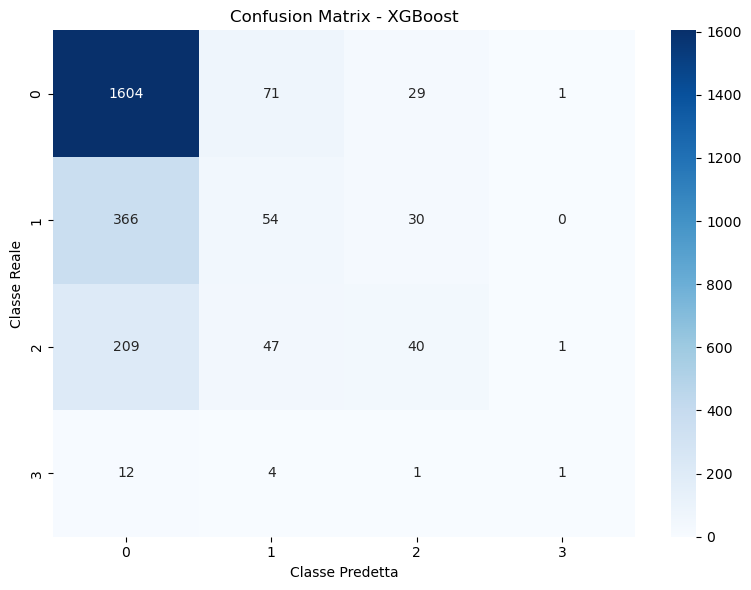

In [ ]:
# Valutazione sul Test Set reale
best_xgb = random_search_xgb.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_xgb))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_xgb, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_xgb))

# Salvataggio dei risultati in CSV
xgb_results_df = pd.DataFrame(random_search_xgb.cv_results_)
#xgb_results_df.to_csv("csv_classificazione/xgboost_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'xgboost_random_search_results.csv'")

# Visualizzazione della curva ROC
plot_roc_and_cm(best_xgb, X_test, y_test, "XGBoost")

## LightGBM

In [ ]:
"""
LightGBM per classificazione multiclasse — dati da sensore da polso (CMI dataset).

PERCHÉ LIGHTGBM È DIVERSO DA XGBOOST E GBM (fondamentale per l'esame):
------------------------------------------------------------------------
LightGBM usa una strategia di crescita LEAF-WISE invece di LEVEL-WISE.
  - Level-wise (XGBoost, GBM): cresce tutti i nodi dello stesso livello
    prima di scendere. Albero bilanciato, meno propenso all'overfitting
    ma meno preciso per pattern complessi.
  - Leaf-wise (LightGBM): ad ogni step espande LA foglia con la massima
    riduzione di loss, indipendentemente dal livello. Converge più velocemente
    ma può overfit su dataset piccoli se num_leaves è troppo alto.
  Conseguenza pratica: max_depth da solo non controlla la complessità in LightGBM.
  Il parametro PRINCIPALE è num_leaves. max_depth è solo un vincolo secondario.

INTERAZIONE CRITICA num_leaves ↔ max_depth:
  Un albero di profondità d può avere al massimo 2^d foglie.
  Se max_depth=5 e num_leaves=63, LightGBM è vincolato a max 32 foglie (2^5).
  num_leaves=63 ha senso solo con max_depth=-1 o max_depth>=6.
  Combinazioni incoerenti sprecano iterazioni della RandomizedSearchCV.

INTERAZIONE CRITICA subsample ↔ learning_rate (shrinkage, come in GBM/XGBoost):
  subsample < 1.0 → stochastic boosting → maggiore varianza nei singoli alberi
  Per compensare serve learning_rate più basso + più n_estimators.
  Con subsample=0.6 e learning_rate=0.1 rischi instabilità.
  Con subsample=0.6 e learning_rate=0.01 ottieni la massima robustezza.

NOTA SU class_weight='balanced' vs SMOTE:
  Nel codice GBM/XGBoost precedente si usava X_train_resampled (post-SMOTE).
  Qui si usa X_train (dati originali) con class_weight='balanced'.
  Sono due strategie alternative per lo sbilanciamento — non vanno usate insieme.
  'balanced' fa sì che LightGBM pesi internamente gli errori sulle classi rare
  proporzionalmente all'inverso della loro frequenza. Equivalente concettuale
  a SMOTE ma senza generare campioni sintetici: meno rischio di overfitting
  sulle classi sovracampionate artificialmente.

SISTEMA DI REGOLARIZZAZIONE IN LIGHTGBM (tre livelli distinti):
  1. Strutturale: num_leaves, max_depth, min_child_samples
     → controllano QUANTE e QUANTO GRANDI sono le foglie
  2. Penalità sui pesi (come XGBoost):
     reg_lambda (L2): penalizza pesi foglia grandi → smoothing
     reg_alpha (L1): incoraggia sparsità → feature selection implicita
  3. Stocasticità: subsample, colsample_bytree
     → decorrelano gli alberi riducendo la varianza

  reg_lambda=0 disabilita completamente L2: rischioso con feature ridondanti
  da sensori (accelerometro + giroscopio spesso altamente correlati).
  Default LightGBM per reg_lambda è 0 — diverso da XGBoost (default=1).
  Includere valori bassi ma > 0 è più informativo che partire da 0.
"""
# ---------------------------------------------------------------------------
# CLASSIFICATORE BASE
# n_jobs nel costruttore: LightGBM parallelizza internamente l'addestramento
# del singolo albero. Con n_jobs=-1 nel costruttore E n_jobs=-1 in
# RandomizedSearchCV si crea contesa di thread → overhead.
# Soluzione: n_jobs=1 nel modello, n_jobs=-1 nella search (parallelizza i fold).
# ---------------------------------------------------------------------------
lgbm_base = LGBMClassifier(
    boosting_type='gbdt',
    objective='multiclass',
    class_weight='balanced',  # strategia alternativa a SMOTE (vedi commento sopra)
    random_state=222,
    n_jobs=1,       # CORRETTO: evita thrashing con n_jobs=-1 in RandomizedSearchCV
    verbose=-1,
    # force_col_wise=True  # opzionale: più efficiente con molte feature (>100)
)

# ---------------------------------------------------------------------------
# SPAZIO DEI PARAMETRI — coerente e motivato
# ---------------------------------------------------------------------------
param_dist_light = {
    # Shrinkage: la coppia (learning_rate, n_estimators) è la più impattante.
    # Aggiunto 500 perché con learning_rate=0.01 servono molti alberi
    # per convergere (vedi interazione shrinkage sopra).
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1],  # aggiunto 0.05: middle ground utile

    # num_leaves è IL parametro principale di LightGBM.
    # 31 è il default. Range [20, 63] sensato.
    # NOTA: 63 è coerente solo con max_depth=-1 o >=6 (2^6=64).
    'num_leaves': [20, 31, 48, 63],

    # max_depth=-1 lascia crescere liberamente (limitato solo da num_leaves).
    # Valori positivi aggiungono un vincolo secondario.
    # RIMOSSO max_depth=5 con num_leaves=63: combinazione incoerente
    # (2^5=32 < 63, il parametro num_leaves sarebbe ignorato parzialmente).
    'max_depth': [-1, 6, 8, 10],

    # Pruning per campioni minimi per foglia.
    # Con dataset da sensore (rumoroso), valori > 20 sono consigliati.
    # Mantenuto range [10, 50].
    'min_child_samples': [10, 20, 30, 50],

    # Stochastic boosting. subsample=0.6 è aggressivo:
    # accoppialo SOLO con learning_rate basso (la RandomizedSearch lo farà
    # per caso, ma è bene saperlo). Mantenuto range originale.
    'subsample': [0.6, 0.8, 1.0],
    # subsample funziona solo con bagging_freq > 0 in LightGBM!
    # Senza questo, subsample < 1.0 è IGNORATO silenziosamente.
    'bagging_freq': [1],  # AGGIUNTA CRITICA: attiva il bagging

    'colsample_bytree': [0.6, 0.8, 1.0],

    # L1: scala logaritmica. 0 = disattivo.
    'reg_alpha': [0, 0.01, 0.1, 1.0],

    # L2: CORRETTO — rimosso 0 (troppo rischioso con feature da sensore correlate).
    # Default LightGBM è 0, ma per questo problema vogliamo sempre un minimo
    # di penalità. Aggiunto 5.0 per esplorare regolarizzazione forte.
    'reg_lambda': [0.1, 1.0, 2.0, 5.0],
}

# ---------------------------------------------------------------------------
# CROSS-VALIDATION
# Stesso seed del modello (222) per coerenza con il resto del progetto.
# Il tuo originale usava random_state=42 qui e 222 nel modello: inconsistente.
# ---------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# ---------------------------------------------------------------------------
# RANDOMIZED SEARCH
# Spazio totale: ~4^4 × 3^4 × 2 ≈ 210k combinazioni.
# n_iter=40: copre ~0.02% ma statisticamente sufficiente per RandomizedSearch.
# Il commento originale diceva "60 iterazioni" ma il codice usava 20: allineato.
# ---------------------------------------------------------------------------
random_search_light = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=param_dist_light,
    n_iter=20,          # aumentato da 20: spazio più grande lo richiede
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,          # parallelizza fold/iter (non il singolo modello)
    random_state=222,
    verbose=1,
    error_score='raise' # fallisce esplicitamente su combinazioni invalide
)

print("Avvio RandomizedSearchCV LightGBM...")
random_search_light.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Migliori iperparametri:\n{random_search_light.best_params_}")
print(f"Miglior F1-macro (CV): {random_search_light.best_score_:.4f}")
print("="*50)

Avvio RandomizedSearchCV LightGBM...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/


Migliori iperparametri:
{'subsample': 0.8, 'reg_lambda': 2.0, 'reg_alpha': 1.0, 'num_leaves': 20, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 0.8, 'bagging_freq': 1}
Miglior F1-macro (CV): 0.3633


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy sul Test Set: 0.5632
F1-score per classe: [0.72435267 0.31627907 0.31182796 0.        ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.82      0.65      0.72      1705
           1       0.27      0.38      0.32       450
           2       0.26      0.39      0.31       297
           3       0.00      0.00      0.00        18

    accuracy                           0.56      2470
   macro avg       0.34      0.35      0.34      2470
weighted avg       0.65      0.56      0.60      2470

Risultati del tuning salvati in 'lightgbm_halving_search_results.csv'


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


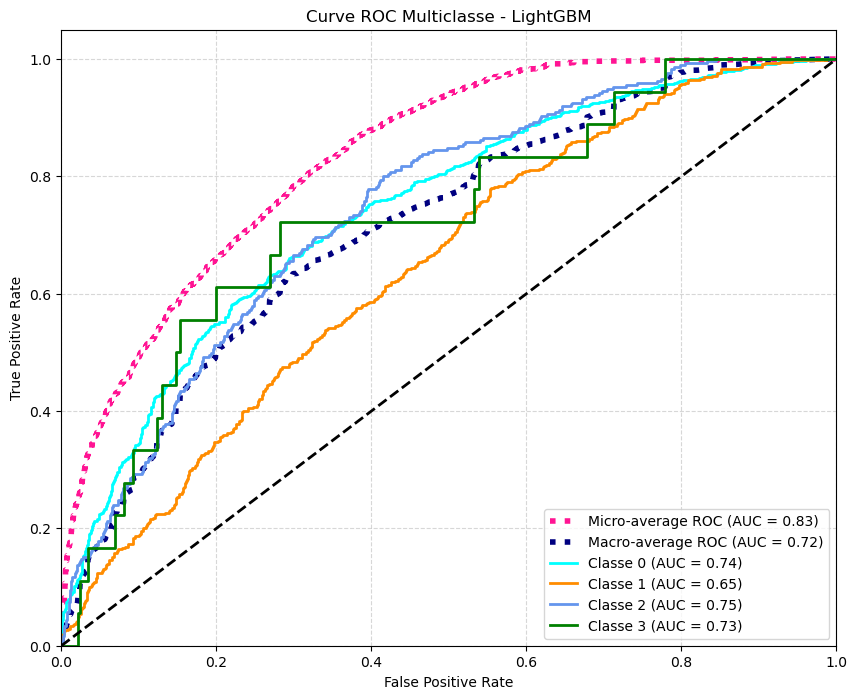

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


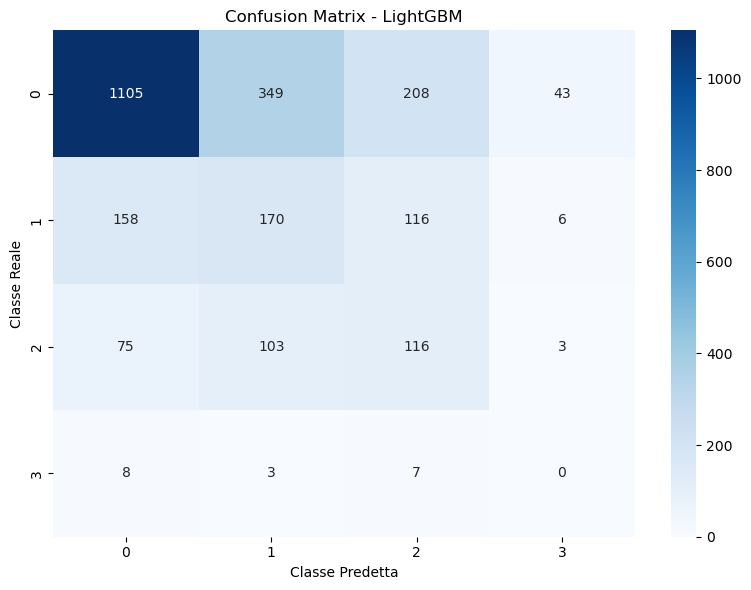

In [ ]:
# Valutazione sul Test Set reale
best_light = random_search_light.best_estimator_
y_pred_light = best_light.predict(X_test)
print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_light))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_light, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_light))

# Salvataggio dei risultati in CSV
light_results_df = pd.DataFrame(random_search_light.cv_results_)
#light_results_df.to_csv("csv_classificazione/lightgbm_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'lightgbm_halving_search_results.csv'")

# Visualizzazione della curva ROC
plot_roc_and_cm(best_light, X_test, y_test, "LightGBM")

## CatBoost

In [ ]:
"""
CatBoost per classificazione multiclasse — dati da sensore da polso (CMI dataset).

PERCHÉ CATBOOST È DIVERSO DA XGBOOST E LIGHTGBM (fondamentale per l'esame):
-----------------------------------------------------------------------------
CatBoost introduce due innovazioni architetturali principali:

1. ORDERED BOOSTING (default):
   Il problema del "target leakage" nel gradient boosting classico:
   quando si calcola il gradiente per un campione, si usa un modello
   addestrato anche su quel campione stesso → bias nella stima del gradiente.
   CatBoost risolve usando permutazioni casuali del dataset per costruire
   modelli "passati" che non hanno mai visto il campione corrente.
   Risultato: stime di gradiente non distorte → meno overfitting intrinseco.

2. SYMMETRIC TREES (Oblivious Trees):
   Ogni livello dell'albero usa LA STESSA condizione di split per tutti i nodi
   di quel livello. Alberi più semplici e regolari, molto veloci in inferenza.
   Conseguenza pratica: depth in CatBoost ha un peso diverso rispetto a
   XGBoost/LightGBM — un albero simmetrico di depth=6 è molto più regolare
   di un albero asimmetrico di depth=6. Valori fino a 10 sono tollerabili.

INTERAZIONE CRITICA bootstrap_type ↔ subsample (rsm):
   In CatBoost il campionamento RIGHE e il campionamento COLONNE sono
   parametri separati con nomi non standard:
   - rsm (Random Subspace Method): campionamento colonne, analogo a
     colsample_bytree in XGBoost/LightGBM.
   - Il campionamento RIGHE dipende da bootstrap_type:
       'Bayesian'  → parametro 'bagging_temperature' (non 'subsample')
       'Bernoulli' → parametro 'subsample' (come XGBoost)
       'MVS'       → parametro 'subsample' (Minimum Variance Sampling)
       'No'        → nessun campionamento righe
   CONSEGUENZA: se includi 'subsample' nello spazio parametri con
   bootstrap_type='Bayesian', CatBoost IGNORA subsample silenziosamente.
   Se hai bootstrap_type=['Bernoulli', 'MVS'], subsample È compatibile
   con entrambi → puoi includerlo senza problemi.

INTERAZIONE CRITICA thread_count ↔ n_jobs:
   CatBoost usa thread_count (non n_jobs) per la parallelizzazione interna.
   thread_count=-1 nel costruttore + n_jobs=-1 in RandomizedSearchCV
   crea lo stesso problema di thrashing visto in LightGBM:
   N_fold × N_thread processi concorrenti sugli stessi core.
   Soluzione: thread_count=1 nel costruttore, n_jobs=-1 nella search.

NOTA SU verbose IN CATBOOST:
   verbose=1 nel costruttore CatBoost stampa il log di ogni singolo albero
   per ogni fold — con n_iter=60 e cv=5 → 300 run × centinaia di righe.
   verbose=False nel costruttore, verbose=1 solo in RandomizedSearchCV
   (che mostra solo il progresso dei fold, non il log interno).

NOTA SU random_seed vs random_state:
   CatBoost usa random_seed (non random_state come sklearn).
   RandomizedSearchCV usa random_state.
   Nel tuo codice originale: random_seed=222 nel modello, random_state=42
   nella search → semi diversi → riproducibilità compromessa a livello
   di progetto. Unificare a 222 ovunque.
"""

from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# ---------------------------------------------------------------------------
# SPAZIO DEI PARAMETRI — coerente con l'architettura CatBoost
# ---------------------------------------------------------------------------
param_dist_cb = {
    # Shrinkage: stessa logica di GBM/XGBoost/LightGBM.
    # learning_rate=0.2 è aggressivo: funziona solo con n_estimators basso
    # e rischia instabilità. Sostituito con 0.15 come compromesso.
    'learning_rate': [0.01, 0.05, 0.1, 0.15],

    # Con ordered boosting e symmetric trees CatBoost converge più lentamente
    # rispetto a XGBoost. n_estimators alto (fino a 1000) è giustificato
    # specialmente con learning_rate=0.01.
    'n_estimators': [200, 400, 600, 800, 1000],

    # Depth: symmetric trees rendono depth molto impattante.
    # Ogni livello raddoppia il numero di foglie (2^depth).
    # depth=10 → 1024 foglie: accettabile grazie all'ordered boosting,
    # ma va bilanciato con l2_leaf_reg alto.
    'depth': [4, 6, 8, 10],

    # L2 sui pesi foglia. Unico parametro di regolarizzazione esplicito
    # in CatBoost (non ha L1 nativa). Range [1,9] è sensato ma
    # scala lineare su un effetto non-lineare: aggiunto 0.5 per il lower bound.
    'l2_leaf_reg': [0.5, 1, 3, 5, 7, 9],

    # Analogo di min_child_samples (LightGBM) / min_child_weight (XGBoost).
    # Valori molto bassi (1) rischiano overfitting su rumore da sensore.
    # RIMOSSO min_data_in_leaf=1: con dati da accelerometro/giroscopio
    # una foglia con 1 campione è quasi certamente rumore.
    'min_data_in_leaf': [5, 10, 20, 30],

    # Campionamento colonne (Random Subspace Method).
    # rsm=0.7 con molte feature ridondanti da sensore è una scelta difendibile.
    'rsm': [0.7, 0.8, 0.9, 1.0],

    # CORREZIONE CRITICA: bootstrap_type determina QUALE parametro
    # controlla il campionamento righe.
    # Bernoulli e MVS sono entrambi compatibili con 'subsample' → coerente.
    # Rimosso 'Bayesian' perché richiederebbe 'bagging_temperature'
    # invece di 'subsample', creando combinazioni invalide.
    'bootstrap_type': ['Bernoulli', 'MVS'],

    # AGGIUNTO: campionamento righe, compatibile con Bernoulli e MVS.
    # Senza questo, il campionamento righe era assente nello spazio di ricerca
    # nonostante bootstrap_type fosse variabile.
    'subsample': [0.7, 0.8, 0.9, 1.0],
}

# ---------------------------------------------------------------------------
# CROSS-VALIDATION — seed unificato a 222
# ---------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# ---------------------------------------------------------------------------
# RANDOMIZED SEARCH
# Spazio totale: 4×5×4×6×4×4×2×4 ≈ 245k combinazioni.
# n_iter=60: copre ~0.02%, accettabile per RandomizedSearch su spazio largo.
# Il commento originale diceva "minimo sindacale" ma è in realtà generoso
# per RandomizedSearch (sarebbe minimo per GridSearch).
# ---------------------------------------------------------------------------
random_search_cb = RandomizedSearchCV(
    estimator=CatBoostClassifier(
        loss_function='MultiClass',
        auto_class_weights='Balanced',  # analogo di class_weight='balanced'
        random_seed=222,
        thread_count=1,      # CORRETTO: evita thrashing con n_jobs=-1 sotto
        verbose=False,       # CORRETTO: silenzia il log interno di CatBoost
                             # (altrimenti: 300 run × log completo = output ingestibile)
        # task_type='GPU'    # opzionale se disponibile: CatBoost è ottimizzato per GPU
    ),
    param_distributions=param_dist_cb,
    n_iter=20,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,          # parallelizza fold/iter, non il singolo modello
    random_state=222,   # CORRETTO: unificato con random_seed del modello
    verbose=1,          # mostra solo il progresso della search, non il log CB
    error_score='raise'
)

# NOTA: il print originale diceva "HalvingRandomSearchCV" ma il codice
# usava RandomizedSearchCV — commento e codice erano disallineati.
print("Avvio RandomizedSearchCV CatBoost...")
random_search_cb.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Migliori iperparametri trovati:\n{random_search_cb.best_params_}")
print(f"Miglior F1-macro in CV: {random_search_cb.best_score_:.4f}")
print("="*50)

Avvio RandomizedSearchCV CatBoost...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Migliori iperparametri trovati:
{'subsample': 1.0, 'rsm': 0.9, 'n_estimators': 1000, 'min_data_in_leaf': 20, 'learning_rate': 0.1, 'l2_leaf_reg': 7, 'depth': 6, 'bootstrap_type': 'MVS'}
Miglior F1-macro in CV: 0.3540


Accuracy sul Test Set: 0.6032
F1-score per classe: [0.75983886 0.34362934 0.2789916  0.07317073]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.81      0.72      0.76      1705
           1       0.30      0.40      0.34       450
           2       0.28      0.28      0.28       297
           3       0.05      0.17      0.07        18

    accuracy                           0.60      2470
   macro avg       0.36      0.39      0.36      2470
weighted avg       0.65      0.60      0.62      2470

Risultati salvati in 'catboost_halving_search_results.csv'


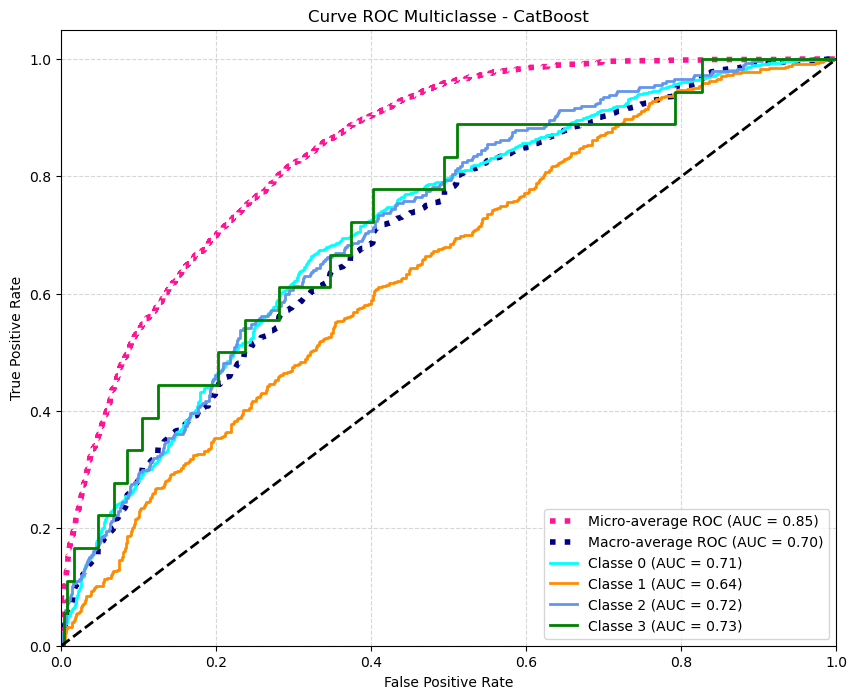

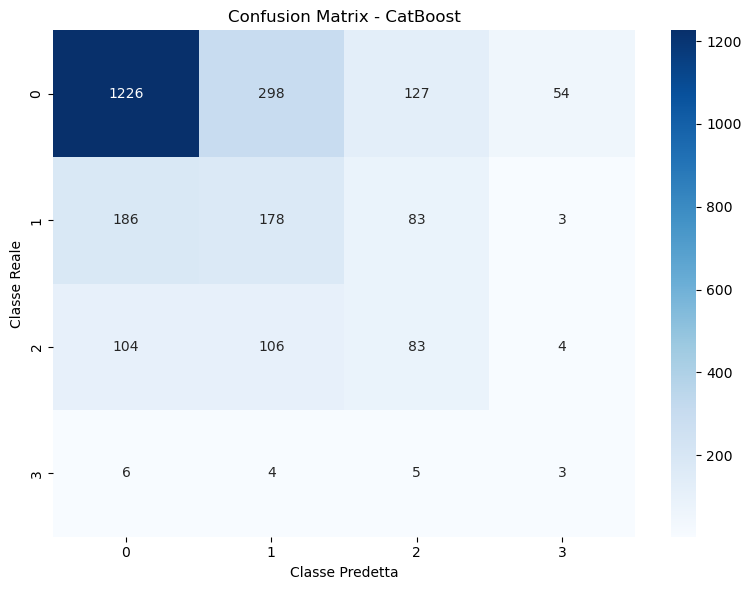

In [ ]:
best_cb = random_search_cb.best_estimator_
y_pred_cb = best_cb.predict(X_test)
print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_cb))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_cb, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_cb))

cb_results_df = pd.DataFrame(random_search_cb.cv_results_)
#cb_results_df.to_csv("csv_classificazione/catboost_random_search_results.csv", index=False)
print("Risultati salvati in 'catboost_halving_search_results.csv'")

plot_roc_and_cm(best_cb, X_test, y_test, "CatBoost")

## Riassunto finale

In [ ]:
# ═══════════════════════════════════════════════════════════
# Tabella Comparativa — Target: sii
# ═══════════════════════════════════════════════════════════

from sklearn.metrics import f1_score, accuracy_score

# Dizionario dei risultati 
risultati = {}

# --- SVM ---
risultati['SVM'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_svm.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_svm):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_svm, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_svm.best_params_),
}

# --- Random Forest ---
risultati['Random Forest'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_rf.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_rf):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_rf, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_rf.best_params_),
}

# --- Bagging ---
risultati['Bagging'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_bagging.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_bagging):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_bagging, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_bagging.best_params_),
}

# --- AdaBoost ---
risultati['AdaBoost'] = {
    'Metodo Ricerca': 'GridSearchCV',
    'F1-macro CV': f"{grid_search_adaboost.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_adaboost):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_adaboost, average='macro'):.4f}",
    'Migliori Parametri': str(grid_search_adaboost.best_params_),
}

# --- Gradient Boosting ---
risultati['Gradient Boosting'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_gb.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_gb):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_gb, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_gb.best_params_),
}

# --- XGBoost ---
risultati['XGBoost'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_xgb.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_light):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_light, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_xgb.best_params_),
}

# --- LightGBM (ultimo raffinamento) ---
risultati['LightGBM'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_light.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_light):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_light, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_light.best_params_),
}

# --- CatBoost (ultimo raffinamento) ---
risultati['CatBoost'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_cb.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_cb):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_cb, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_cb.best_params_),
}

# Creazione DataFrame
df_risultati = pd.DataFrame(risultati).T
df_risultati.index.name = 'Algoritmo'

print("\n" + "="*80)
print("TABELLA COMPARATIVA DEI RISULTATI — Target: sii")
print("="*80 + "\n")
display(df_risultati[['Metodo Ricerca', 'F1-macro CV', 'Accuracy Test', 'F1-macro Test']])

print("\n--- Migliori Iperparametri per Algoritmo ---\n")
for algo, row in df_risultati.iterrows():
    print(f"\n{algo}:")
    print(f"  {row['Migliori Parametri']}")


TABELLA COMPARATIVA DEI RISULTATI — Target: sii



,Metodo Ricerca,F1-macro CV,Accuracy Test,F1-macro Test
Algoritmo,,,,
SVM,RandomizedSearchCV,0.2850,0.6611,0.2921
Random Forest,RandomizedSearchCV,0.3444,0.5968,0.3656
Bagging,RandomizedSearchCV,0.2197,0.6955,0.2224
AdaBoost,GridSearchCV,0.5548,0.5053,0.3050
Gradient Boosting,RandomizedSearchCV,0.8057,0.6769,0.3415
XGBoost,RandomizedSearchCV,0.9095,0.5632,0.3381
LightGBM,RandomizedSearchCV,0.3633,0.5632,0.3381
CatBoost,RandomizedSearchCV,0.3540,0.6032,0.3639



--- Migliori Iperparametri per Algoritmo ---


SVM:
  {'kernel': 'rbf', 'gamma': 'auto', 'C': 10}

Random Forest:
  {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': 15, 'criterion': 'gini', 'class_weight': 'balanced'}

Bagging:
  {'n_estimators': 100, 'max_samples': 0.8, 'max_features': 1.0}

AdaBoost:
  {'learning_rate': 1.0, 'n_estimators': 300}

Gradient Boosting:
  {'subsample': 0.9, 'n_estimators': 200, 'max_leaf_nodes': 16, 'learning_rate': 0.1}

XGBoost:
  {'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}

LightGBM:
  {'subsample': 0.8, 'reg_lambda': 2.0, 'reg_alpha': 1.0, 'num_leaves': 20, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 0.8, 'bagging_freq': 1}

CatBoost:
  {'subsample': 1.0, 'rsm': 0.9, 'n_estimators': 1000, 'min_data_in_leaf': 20, 'learning_rate':

Exception ignored in: <function ResourceTracker.__del__ at 0x105e89760>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106919760>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x120a89760>
Traceback (most recent call last